In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import pathlib

In [2]:
print("TensorFlow:", tf.__version__)
np.random.seed(42)
tf.random.set_seed(42)

TensorFlow: 2.19.0


In [3]:
# Load cleaned data
df = pd.read_csv("output_with_thermal_anomaly.csv")
print(df.head())
print(df.info())

             timestamp   user_id                       _id  temperature  \
0  2026-04-01 21:45:03  user_001  69cd91e2fd35102c3c5ac1d1         27.5   
1  2026-04-01 21:45:04  user_001  69cd91e4fd35102c3c5ac1d2         27.5   
2  2026-04-01 21:45:05  user_001  69cd91e5fd35102c3c5ac1d3         26.6   
3  2026-04-01 21:45:07  user_001  69cd91e6fd35102c3c5ac1d4         26.6   
4  2026-04-01 21:45:08  user_001  69cd91e8fd35102c3c5ac1d5         26.6   

   humidity  light_intensity  sound_level session_date  thermal_anomaly  
0      55.3             5.00           14   2026-04-01                0  
1      55.3             5.00           28   2026-04-01                0  
2      56.0             4.17           41   2026-04-01                0  
3      56.0             5.00           55   2026-04-01                0  
4      56.0             4.17           68   2026-04-01                0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61315 entries, 0 to 61314
Data columns (total 9 columns

In [4]:
# Fix missing labels
df["thermal_anomaly"] = df["thermal_anomaly"].fillna(0)

In [5]:
# Select features - Temperature & Humidity
features = ["temperature", "humidity"]

In [6]:
# Drop missing
df = df.dropna(subset=features + ["thermal_anomaly"])

In [7]:
X = df[features].values.astype("float32")
y = df["thermal_anomaly"].values.astype("int32")

In [8]:
print("Shape:", X.shape, y.shape)
print("Class balance:", np.bincount(y))

Shape: (61315, 2) (61315,)
Class balance: [41241 20074]


In [9]:
# Normalize
scaler = MinMaxScaler()
X = scaler.fit_transform(X)

In [10]:
# Save scaler params for ESP32
scaler_min = scaler.data_min_
scaler_max = scaler.data_max_

In [11]:
print("Min (temp, humidity):", scaler_min)
print("Max (temp, humidity):", scaler_max)

Min (temp, humidity): [24.  48.9]
Max (temp, humidity): [31.9 86.5]


In [12]:
# Save to file for reference
np.savetxt("scaler_params.txt",
           np.vstack([scaler_min, scaler_max]),
           header="min_temp,min_humidity\nmax_temp,max_humidity",
           fmt='%.4f')

In [13]:
# Train-test split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [14]:
print("Train:", X_train.shape, "Val:", X_val.shape)

Train: (49052, 2) Val: (12263, 2)


In [15]:
# Build model - Smaller for ESP32
model = keras.Sequential([
    layers.Input(shape=(2,)),   # 2 inputs: temp, humidity
    layers.Dense(8, activation="relu"),
    layers.Dense(4, activation="relu"),
    layers.Dense(2, activation="softmax")  # 2 classes: Normal, Abnormal
])

In [16]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [17]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            10 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 70 (280.00 B)

 Trainable params: 70 (280.00 B)

 Non-trainable params: 0 (0.00 B)

In [18]:
# Train
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=16,
    verbose=1
)

Epoch 1/20
3066/3066 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.9933 - loss: 0.0211 - val_accuracy: 0.9972 - val_loss: 0.0072
Epoch 2/20
3066/3066 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.9960 - loss: 0.0100 - val_accuracy: 0.9986 - val_loss: 0.0069
Epoch 3/20
3066/3066 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.9962 - loss: 0.0094 - val_accuracy: 0.9987 - val_loss: 0.0065
Epoch 4/20
3066/3066 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.9964 - loss: 0.0092 - val_accuracy: 0.9985 - val_loss: 0.0064
Epoch 5/20
3066/3066 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.9965 - loss: 0.0089 - val_accuracy: 0.9982 - val_loss: 0.0067
Epoch 6/20
3066/3066 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.9966 - loss: 0.0086 - val_accuracy: 0.9982 - val_loss: 0.0067
Epoch 7/20
3066/3066 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.9968 - loss: 0.0082 - val_accuracy: 0.9983 - val_loss: 0.0061
Epoch 8/20
3066/3066 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.9968 - loss: 0.0078 - 

In [19]:
# Plot results
plt.figure(figsize=(12, 4))

<Figure size 1200x400 with 0 Axes>

<Figure size 1200x400 with 0 Axes>

Text(0.5, 1.0, 'Accuracy')

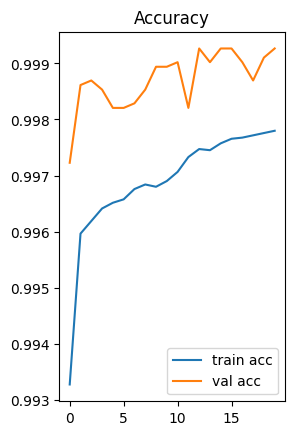

In [20]:
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train acc")
plt.plot(history.history["val_accuracy"], label="val acc")
plt.legend()
plt.title("Accuracy")

Text(0.5, 1.0, 'Loss')

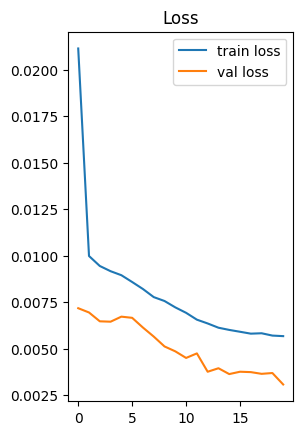

In [21]:
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.legend()
plt.title("Loss")

In [22]:
plt.tight_layout()
plt.savefig("training_history.png")
plt.show()

<Figure size 640x480 with 0 Axes>

In [23]:
# Evaluate
val_loss, val_acc = model.evaluate(X_val, y_val)
print(f"\nValidation Accuracy: {val_acc:.3f}")
print(f"Validation Loss: {val_loss:.3f}")

384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9993 - loss: 0.0031

Validation Accuracy: 0.999
Validation Loss: 0.003


In [24]:
# Test predictions
sample = X_val[:10]
preds = model.predict(sample)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step


In [25]:
print("\nSample Predictions:")
for i, p in enumerate(preds):
    pred_class = np.argmax(p)
    actual = y_val[i]
    status = 'ABNORMAL' if pred_class == 1 else 'NORMAL'
    print(f"Sample {i}: Pred={status} (conf={p[pred_class]:.2f}) | Actual={'ABNORMAL' if actual==1 else 'NORMAL'}")


Sample Predictions:
Sample 0: Pred=NORMAL (conf=1.00) | Actual=NORMAL
Sample 1: Pred=NORMAL (conf=1.00) | Actual=NORMAL
Sample 2: Pred=ABNORMAL (conf=1.00) | Actual=ABNORMAL
Sample 3: Pred=ABNORMAL (conf=1.00) | Actual=ABNORMAL
Sample 4: Pred=NORMAL (conf=1.00) | Actual=NORMAL
Sample 5: Pred=ABNORMAL (conf=1.00) | Actual=ABNORMAL
Sample 6: Pred=ABNORMAL (conf=1.00) | Actual=ABNORMAL
Sample 7: Pred=ABNORMAL (conf=1.00) | Actual=ABNORMAL
Sample 8: Pred=ABNORMAL (conf=1.00) | Actual=ABNORMAL
Sample 9: Pred=NORMAL (conf=1.00) | Actual=NORMAL


In [26]:
# Convert to TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

Saved artifact at '/tmp/tmpatrfpsx9'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 2), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  132577945700496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132577945701648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132577945700304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132577945698768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132577945702224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132577945699152: TensorSpec(shape=(), dtype=tf.resource, name=None)


In [27]:
out_dir = pathlib.Path("export")
out_dir.mkdir(exist_ok=True)

In [28]:
tflite_path = out_dir / "thermal_model.tflite"
tflite_path.write_bytes(tflite_model)

2400

In [29]:
print(f"\nSaved: {tflite_path} | Size: {tflite_path.stat().st_size} bytes")


Saved: export/thermal_model.tflite | Size: 2400 bytes


In [30]:
# Quantized version
converter_q = tf.lite.TFLiteConverter.from_keras_model(model)
converter_q.optimizations = [tf.lite.Optimize.DEFAULT]

In [31]:
tflite_model_q = converter_q.convert()

Saved artifact at '/tmp/tmpvtkk9d0f'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 2), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  132577945700496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132577945701648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132577945700304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132577945698768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132577945702224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132577945699152: TensorSpec(shape=(), dtype=tf.resource, name=None)


In [32]:
tflite_q_path = out_dir / "thermal_model_quant.tflite"
tflite_q_path.write_bytes(tflite_model_q)

2400

In [33]:
print(f"Saved: {tflite_q_path} | Size: {tflite_q_path.stat().st_size} bytes")

Saved: export/thermal_model_quant.tflite | Size: 2400 bytes


In [34]:
# Test TFLite model
def run_tflite(tflite_bytes, inputs):
    interpreter = tf.lite.Interpreter(model_content=tflite_bytes)
    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    outputs = []
    for x in inputs:
        interpreter.set_tensor(input_details[0]["index"], x.reshape(1, 2))
        interpreter.invoke()
        out = interpreter.get_tensor(output_details[0]["index"])
        outputs.append(out[0])

    return np.array(outputs)

In [35]:
test = X_val[:5]
print("\nTFLite output (should match Keras):")
print(run_tflite(tflite_model, test))


TFLite output (should match Keras):
[[1.0000000e+00 3.0371329e-08]
 [1.0000000e+00 4.3010318e-11]
 [1.1258704e-31 1.0000000e+00]
 [7.0355213e-26 1.0000000e+00]
 [1.0000000e+00 9.6711994e-10]]


/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [36]:
# Convert to C header
def tflite_to_c_array(tflite_bytes, var_name):
    hex_array = ", ".join([f"0x{b:02x}" for b in tflite_bytes])
    return f"""
#ifndef {var_name.upper()}_H
#define {var_name.upper()}_H

const unsigned char {var_name}[] = {{
{hex_array}
}};

const unsigned int {var_name}_len = sizeof({var_name});

#endif
"""

In [37]:
header = tflite_to_c_array(tflite_model_q, "thermal_model_tflite")

In [38]:
with open("export/thermal_model.h", "w") as f:
    f.write(header)

print("\nthermal_model.h generated!")


thermal_model.h generated!


In [39]:
# Download files (in Colab)
from google.colab import files

In [40]:
files.download("export/thermal_model.tflite")
files.download("export/thermal_model_quant.tflite")
files.download("export/thermal_model.h")
files.download("scaler_params.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>